In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.core.viz.style import apply_style, ITALY_C, EU_C, PEER_C
apply_style()


# Phase 3 — Comparative Evaluation: Administrative Cycles, Lagged Two-Way FE & Placebo Ranking

This notebook synthesizes the four pillars across **Cesena** (`040007`) and the 12 Emilia-Romagna peer municipalities (`N = 13` municipalities, `2008–2025`) to answer two empirical questions:
1. **How did Cesena perform across its administrative cycles (`Lucchi I 2009–2014`, `Lucchi II 2014–2019`, `Lattuca I 2019–2024`, `Lattuca II 2024+`) relative to Core Peers and All ER Peers?**
2. **Across the 13 Emilia-Romagna municipalities, do municipal fiscal and investment levers at year $t$ predict real-economy, income, or demographic changes at $t+1 \dots t+4$ after absorbing municipality and year Fixed Effects?**

**Statistical Rigor & Identification Limits:**
- **Stationarity transforms:** Outcome series are transformed to annual log growth rates (`dlog_*`, $\times 100$) or first differences (`diff_*`) before entering the panel regressions.
- **Two-Way Fixed Effects (`twoway_fe_regression`):** Every specification absorbs municipality fixed effects ($\alpha_c$, time-invariant city traits) and year fixed effects ($\tau_t$, common regional macro shocks), with standard errors clustered by municipality (`CR1` small-sample correction) and a within-year permutation $p$-value (`p_perm`, 5,000 permutations).
- **Benjamini-Hochberg FDR (`bh_fdr`) & Shuffled Null Check (`shuffled_null_check`):** We control the false discovery rate across all 140 tested predictor-outcome-lag pairs (`q_bh_perm`, `q_bh_cluster`) and run repeated shuffled panels to check calibration.
- **Placebo Ranking for Cesena-Specific Claims (`cesena_placebo_ranking`):** Because Cesena is a single cluster (`N = 1`), any claim about Cesena's long-run trajectory is evaluated via its rank among the 13 ER municipalities (`rank_1_to_13`). With 13 municipalities, the smallest attainable two-sided placebo rank proportion is $2/13 = 0.154$, so single-city rankings are reported as descriptive orderings. Descriptive only, never causal.

In [2]:
from cifresignificative.studies.cesena.analysis.data import (
    load_panel_comuni, load_administrations, load_scorecard, load_lagged_fe,
    load_placebo_ranking, load_extended_placebo_ranking, load_synthetic_cesena, load_synthetic_summary,
    load_synthetic_in_space, load_synthetic_in_time, load_flood_shock,
)
from cifresignificative.studies.cesena.analysis.experiments import (
    shuffled_null_check,
)
from cifresignificative.studies.cesena.analysis.flood import (
    compare_flood_tiers,
)

panel = load_panel_comuni()
admins = load_administrations()
scorecard = load_scorecard()
lagged_fe = load_lagged_fe()
ranking = load_placebo_ranking()
ext_ranking = load_extended_placebo_ranking()
synth_series = load_synthetic_cesena()
synth_summary = load_synthetic_summary()
synth_in_space = load_synthetic_in_space()
synth_in_time = load_synthetic_in_time()
flood_df = load_flood_shock()
flood_tiers = compare_flood_tiers(flood_df)

print("Cesena municipal administrative cycles (data/external/cesena_administrations.csv):")
display(admins)

Cesena municipal administrative cycles (data/external/cesena_administrations.csv):


,mandate,mayor,coalition,start,end,election_date,evidence,source
0,Lucchi I,Paolo Lucchi,Centrosinistra,2009-06-22,2014-05-26,2009-06-21,verified,Ministero dell'Interno Eligendo - Comunali 200...
1,Lucchi II,Paolo Lucchi,Centrosinistra,2014-05-26,2019-06-10,2014-05-25,verified,Ministero dell'Interno Eligendo - Comunali 201...
2,Lattuca I,Enzo Lattuca,Centrosinistra,2019-06-10,2024-06-10,2019-06-09,verified,Ministero dell'Interno Eligendo - Comunali 201...
3,Lattuca II,Enzo Lattuca,Centrosinistra,2024-06-10,NaT,2024-06-09,verified,Ministero dell'Interno Eligendo - Comunali 202...


## 1. Administrative Cycle Scorecard: Cesena vs. Core Peers & All ER Peers
We compare Cesena's period averages against the 6 Core Peers and all 12 ER Peers across `Lucchi I (2009–2014)`, `Lucchi II (2014–2019)`, `Lattuca I (2019–2024)`, and `Lattuca II (2024+)`. Recall that `Lucchi I` falls under the `D.P.R. 194/1996` accounting regime while `Lattuca I` falls under harmonized `D.Lgs. 118/2011` accounting (`Lucchi II` spans the 2016 transition), so fiscal levels are always compared *against peers in the same cycle*, never as an unadjusted cross-regime time trend.

In [3]:
piv_sc = scorecard.pivot(
    index=["metric", "metric_label"],
    columns="administration",
    values=["cesena", "core_peer_median", "gap_vs_core", "rank_1_to_13"],
)
order_cols = ["Lucchi I (2009-2014)", "Lucchi II (2014-2019)", "Lattuca I (2019-2024)", "Lattuca II (2024+)"]
avail_cols = [c for c in order_cols if c in scorecard["administration"].unique()]
for cyc in avail_cols:
    print(f"\n=== {cyc} ===")
    sub = scorecard[scorecard["administration"] == cyc][[
        "metric_label", "cesena", "core_peer_median", "er_peer_median", "gap_vs_core", "gap_vs_er", "rank_1_to_13", "n_comuni"
    ]]
    display(sub.round(2))


=== Lucchi I (2009-2014) ===


,metric_label,cesena,core_peer_median,er_peer_median,gap_vs_core,gap_vs_er,rank_1_to_13,n_comuni
0,Current spending per capita (2020 EUR),828.92,924.89,937.51,-95.97,-108.58,13,13
1,Capital spending per capita (2020 EUR),217.62,172.69,173.23,44.93,44.38,5,13
2,Capital share of primary spending (%),20.46,15.26,15.26,5.20,5.20,5,13
3,Own taxes & fees per capita (2020 EUR),376.68,427.52,439.09,-50.85,-62.41,12,13
4,MEF IRPEF surcharge per capita (2020 EUR),58.43,73.94,81.16,-15.52,-22.73,12,13
5,Official rigidity index (%),39.29,44.95,42.80,-5.66,-3.51,8,13
6,Current revenue collection rate (%),104.88,101.82,100.51,3.06,4.37,1,13
7,Cohesion/national project allocations per capi...,2.36,0.00,0.00,2.36,2.36,4,13
8,"Active local units per 1,000 inhabitants",98.96,101.05,103.14,-2.09,-4.18,9,13
9,"Private employees per 1,000 inhabitants",378.52,373.74,388.01,4.77,-9.49,8,13



=== Lucchi II (2014-2019) ===


,metric_label,cesena,core_peer_median,er_peer_median,gap_vs_core,gap_vs_er,rank_1_to_13,n_comuni
16,Current spending per capita (2020 EUR),850.28,968.07,979.81,-117.80,-129.53,12,13
17,Capital spending per capita (2020 EUR),162.56,120.36,132.81,42.20,29.75,4,13
18,Capital share of primary spending (%),15.84,11.47,11.85,4.37,3.99,3,13
19,Own taxes & fees per capita (2020 EUR),541.37,635.32,654.89,-93.96,-113.52,12,13
20,MEF IRPEF surcharge per capita (2020 EUR),65.55,85.59,92.17,-20.03,-26.62,12,13
21,Official rigidity index (%),28.01,27.63,28.60,0.38,-0.59,8,13
22,Current revenue collection rate (%),96.92,94.79,98.67,2.13,-1.75,8,13
23,Cohesion/national project allocations per capi...,69.73,81.86,81.31,-12.13,-11.58,7,13
24,"Active local units per 1,000 inhabitants",97.06,96.13,98.14,0.93,-1.09,8,13
25,"Private employees per 1,000 inhabitants",386.57,362.52,377.59,24.05,8.98,6,13



=== Lattuca I (2019-2024) ===


,metric_label,cesena,core_peer_median,er_peer_median,gap_vs_core,gap_vs_er,rank_1_to_13,n_comuni
32,Current spending per capita (2020 EUR),841.14,946.21,990.55,-105.07,-149.41,9,13
33,Capital spending per capita (2020 EUR),188.06,150.21,157.18,37.85,30.88,4,13
34,Capital share of primary spending (%),17.81,14.76,13.64,3.05,4.17,4,13
35,Own taxes & fees per capita (2020 EUR),519.72,557.53,610.07,-37.81,-90.35,8,13
36,MEF IRPEF surcharge per capita (2020 EUR),70.36,94.00,100.52,-23.64,-30.17,13,13
37,Current revenue collection rate (%),95.98,95.54,96.19,0.44,-0.22,8,13
38,Cohesion/national project allocations per capi...,38.08,68.35,81.24,-30.27,-43.16,13,13
39,"Active local units per 1,000 inhabitants",97.05,95.87,99.72,1.18,-2.67,7,13
40,"Private employees per 1,000 inhabitants",407.62,379.81,400.27,27.81,7.35,7,13
41,Average unit size (employees / local unit),4.20,4.28,4.25,-0.07,-0.05,8,13



=== Lattuca II (2024+) ===


,metric_label,cesena,core_peer_median,er_peer_median,gap_vs_core,gap_vs_er,rank_1_to_13,n_comuni
47,MEF IRPEF surcharge per capita (2020 EUR),75.40,103.74,118.27,-28.34,-42.87,13,13
48,Cohesion/national project allocations per capi...,3.16,1.82,2.09,1.34,1.07,4,13
49,"Active local units per 1,000 inhabitants",101.35,98.28,102.84,3.07,-1.49,7,13
50,"Private employees per 1,000 inhabitants",439.20,402.30,418.73,36.89,20.47,5,13
51,Average unit size (employees / local unit),4.33,4.26,4.26,0.07,0.07,5,13
52,Real mean IRPEF income (2020 EUR),23138.16,22815.62,24188.19,322.54,-1050.03,8,13
53,Real median IRPEF income (2020 EUR),19276.51,19635.90,20285.51,-359.39,-1009.01,11,13
54,Local IRPEF Gini index (Pareto-adjusted),0.39,0.38,0.40,0.01,-0.01,9,13
55,Old-age dependency / aging index (65+ / 0-14 x...,232.91,213.95,210.22,18.96,22.69,3,13
56,25-44 working-age cohort net attractiveness (p...,12.87,17.86,15.41,-4.99,-2.54,11,13


## 2. Cesena's Long-Run Placebo Ranking Among the 13 Emilia-Romagna Municipalities
Where does Cesena (`040007`) rank among all 13 Emilia-Romagna municipalities on cumulative employment growth, local unit dynamics, firm scale, real household income growth, inequality, demographic aging, working-age attractiveness, and harmonized fiscal execution?

Cesena Long-Run Placebo Ranking among the 13 Emilia-Romagna Municipalities (rank 1 = highest value):


,label,period,cesena_value,peer_median_ex_cesena,peer_min,peer_max,gap_vs_peer_median,rank_1_to_13,n_comuni,placebo_two_sided_prop
0,Private employment cumulative growth (%),2012-2024,14.78,9.98,4.03,16.47,4.79,4,13,0.62
1,Active local units cumulative change (%),2012-2024,1.42,3.28,-2.09,8.34,-1.87,10,13,0.62
2,Average firm size change (employees/unit),2012-2024,0.50,0.24,0.04,0.46,0.27,1,13,0.15
3,Real mean IRPEF income cumulative growth (%),2008-2024,4.76,-0.90,-2.60,3.40,5.66,1,13,0.15
4,Real median IRPEF income cumulative growth (%),2008-2024,7.58,0.75,-1.65,6.85,6.83,1,13,0.15
5,Local Gini index change (pts),2008-2024,-0.02,-0.01,-0.03,-0.00,-0.01,11,13,0.46
6,Resident population change (%),2008-2025,1.34,5.14,-2.54,15.43,-3.80,12,13,0.31
7,Old-age index change (pts),2008-2025,52.62,30.26,-37.88,56.03,22.35,2,13,0.31
8,Mean 25-44 cohort net attractiveness (per 1k/yr),2012-2024,7.98,12.65,10.12,23.16,-4.67,13,13,0.15
9,Mean harmonized capital spending per capita (2...,2016-2021,165.94,150.15,81.92,329.36,15.79,7,13,1.00


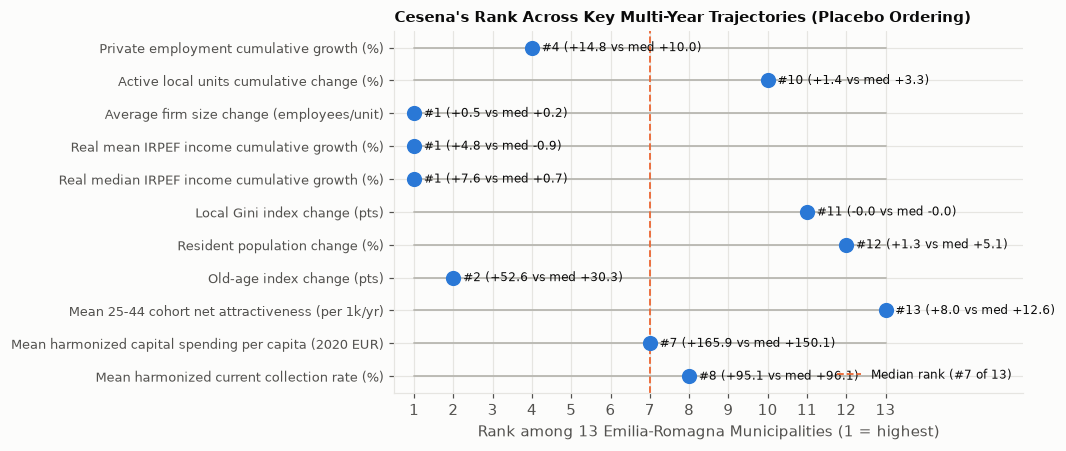

In [4]:
print("Cesena Long-Run Placebo Ranking among the 13 Emilia-Romagna Municipalities (rank 1 = highest value):")
display(ranking[[
    "label", "period", "cesena_value", "peer_median_ex_cesena",
    "peer_min", "peer_max", "gap_vs_peer_median", "rank_1_to_13", "n_comuni", "placebo_two_sided_prop",
]].round(2))

fig, ax = plt.subplots(figsize=(9.5, 4.2))
r_plot = ranking.iloc[::-1]
y = np.arange(len(r_plot))
ax.scatter(r_plot["rank_1_to_13"], y, s=80, color=ITALY_C, zorder=3)
for i, (_, r) in enumerate(r_plot.iterrows()):
    ax.plot([1, r["n_comuni"]], [i, i], color=PEER_C, lw=1.2, zorder=1)
    ax.text(r["rank_1_to_13"] + 0.25, i, f"#{int(r['rank_1_to_13'])} ({r['cesena_value']:+.1f} vs med {r['peer_median_ex_cesena']:+.1f})", fontsize=8, va="center")
ax.axvline(7, color=EU_C, ls="--", lw=1.2, label="Median rank (#7 of 13)")
ax.set_yticks(y, r_plot["label"], fontsize=8.5)
ax.set_xlim(0.5, 16.5)
ax.set_xticks(range(1, 14))
ax.set_xlabel("Rank among 13 Emilia-Romagna Municipalities (1 = highest)")
ax.set_title("Cesena's Rank Across Key Multi-Year Trajectories (Placebo Ordering)", fontsize=9.5)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

## 3. Two-Way Fixed Effects Lagged Screen ($t \to t+1 \dots t+4$), BH-FDR Control & Shuffled Null Check
We screen 5 policy/fiscal predictors against 7 stationary economic, income, and demographic outcomes across lags $k \in \{1, 2, 3, 4\}$ years (`140` tests total), controlling for municipality FE and year FE. We also run repeated shuffled panels; they show the test over-rejects, so it could not support a positive result.

In [5]:
null_res = shuffled_null_check(panel, lags=(1, 2, 3, 4), seed=12345)
print("Shuffled-municipality placebo null check:", null_res)

print(f"\nTotal lagged Two-Way FE tests: {len(lagged_fe)}")
print(f"Tests with unadjusted p_perm < 0.05: {int((lagged_fe['p_perm'] < 0.05).sum())} | p_cluster < 0.05: {int((lagged_fe['p_cluster'] < 0.05).sum())}")
print(f"Tests surviving BH-FDR q_bh_perm < 0.05: {int((lagged_fe['q_bh_perm'] < 0.05).sum())} | q_bh_cluster < 0.05: {int((lagged_fe['q_bh_cluster'] < 0.05).sum())}")
print(f"Tests surviving q_bh_perm < 0.10: {int((lagged_fe['q_bh_perm'] < 0.10).sum())} | q_bh_cluster < 0.10: {int((lagged_fe['q_bh_cluster'] < 0.10).sum())}")

print("\nTop 15 Lagged Two-Way FE Associations (sorted by permutation p-value):")
display(lagged_fe.head(15)[[
    "predictor_label", "outcome_label", "lag_years", "regime_scope",
    "n_obs", "n_comuni", "n_years", "beta_std", "t_stat", "p_cluster", "p_perm", "q_bh_cluster", "q_bh_perm", "r2_within",
]].round(3))

Shuffled-municipality placebo null check: {'n_tests': 140, 'n_rep': 20, 'n_discoveries_q_perm_05': 14, 'n_discoveries_q_cluster_05': 3, 'share_runs_with_discovery': 0.25, 'min_q_perm': 0.017491254372813594, 'min_p_perm': 0.0004997501249375312}

Total lagged Two-Way FE tests: 140
Tests with unadjusted p_perm < 0.05: 5 | p_cluster < 0.05: 8
Tests surviving BH-FDR q_bh_perm < 0.05: 0 | q_bh_cluster < 0.05: 0
Tests surviving q_bh_perm < 0.10: 0 | q_bh_cluster < 0.10: 0

Top 15 Lagged Two-Way FE Associations (sorted by permutation p-value):


,predictor_label,outcome_label,lag_years,regime_scope,n_obs,n_comuni,n_years,beta_std,t_stat,p_cluster,p_perm,q_bh_cluster,q_bh_perm,r2_within
0,Current revenue collection capacity (%),Active local units growth (log pts x100),2,dlgs118,78,13,6,0.353,2.016,0.067,0.007,0.747,0.518,0.125
1,Current revenue collection capacity (%),Active local units growth (log pts x100),4,dlgs118,65,13,5,-0.342,-1.709,0.113,0.007,0.747,0.518,0.117
2,Public project disbursements per capita (2020 ...,"25-44 cohort net attractiveness (per 1,000)",4,all,182,13,14,-0.169,-2.394,0.034,0.021,0.670,0.903,0.029
3,Public project allocations per capita (2020 EUR),"25-44 cohort net attractiveness (per 1,000)",4,all,182,13,14,-0.163,-2.546,0.026,0.031,0.670,0.903,0.026
4,Structural budget rigidity proxy (%),Private employment growth (log pts x100),4,dlgs118,65,13,5,-0.296,-2.364,0.036,0.044,0.670,0.903,0.088
5,Current revenue collection capacity (%),Real IRPEF tax base per capita growth (log pts...,2,dlgs118,78,13,6,0.233,1.075,0.304,0.051,0.836,0.903,0.054
6,Current revenue collection capacity (%),Real IRPEF tax base per capita growth (log pts...,4,dlgs118,65,13,5,-0.234,-1.334,0.207,0.071,0.805,0.903,0.055
7,Public project disbursements per capita (2020 ...,Active local units growth (log pts x100),3,all,156,13,12,-0.160,-1.811,0.095,0.075,0.747,0.903,0.026
8,Capital share of primary spending (%),Active local units growth (log pts x100),4,all,156,13,12,-0.145,-1.519,0.155,0.113,0.747,0.903,0.021
9,Public project allocations per capita (2020 EUR),Active local units growth (log pts x100),3,all,156,13,12,-0.160,-1.671,0.121,0.119,0.747,0.903,0.026


## 4. Expanding Cross-Sectional Power ($N = 36, 45, 73, 83$ Municipal Pools) & Synthetic Control for Cesena (`2019–2024`)
Because the 13-city regional benchmark (`N = 13`) caps the smallest attainable two-sided placebo rank proportion at $2/13 = 0.154$, we perform two complementary robustness exercises:
1. **Extended MEF Municipal Placebo Ranking (`extended_mef_placebo_ranking`):** Using the full national MEF IRPEF open-data archives (`2008` vs `2024`), we rank Cesena (`C573`, `77,117` taxpayers in 2024) across four progressively broader municipal donor pools:
   - **All 36 Emilia-Romagna municipalities with $\ge 15,000$ taxpayers** (`ER_15k_payers`, $N = 36$);
   - **All 73 Emilia-Romagna municipalities with $\ge 10,000$ taxpayers** (`ER_10k_payers`, $N = 73$);
   - **All 45 Northern & Central Italian mid-sized cities with `40,000–120,000` taxpayers** (`NC_midsize_40k_120k`, $N = 45$);
   - **All 83 Italian mid-sized cities with `40,000–120,000` taxpayers** (`IT_midsize_40k_120k`, $N = 83$).
2. **Convex Synthetic Control for Cesena (`synthetic_cesena`):** Following the synthetic-control design (`w_j >= 0`, `sum(w_j) = 1`), we match Cesena's pre-2019 cumulative trajectory (`t_0 .. 2018`; 2019 is a split chosen after seeing the data, so ranks are descriptive) from the donor pool of ER peers and evaluate the `2019–2024` post-2018 gap.
3. **In-Space and In-Time Placebos (`synthetic_control_placebos`):**
   - **In-space placebos (donor permutations):** Iteratively assign each of the 12 peer municipalities as a pseudo-treated unit, evaluating the distribution of post-treatment gaps and post-to-pre RMSPE ratios ($r_j = \text{RMSPE}_{\text{post}, j} / \text{RMSPE}_{\text{pre}, j}$) to compute exact permutation $p$-values.
   - **In-time placebos (pseudo-treatment year 2014):** Re-fit Synthetic Cesena on pre-2015 trajectories ($\le 2014$) to verify that no artificial gap emerges in `2015–2018` before the true 2019 divergence.

1. Extended MEF Municipal Placebo Ranking (N=36, 73 ER municipalities; N=45 Northern/Central & N=83 Italian mid-sized cities):


,pool_label,metric_label,cesena_value,peer_median_ex_cesena,gap_vs_peer_median,rank,n_comuni,placebo_two_sided_p,below_05
0,Emilia-Romagna municipalities >=15k taxpayers,Real mean IRPEF income growth 2008-2024 (%),4.761,-0.017,4.778,4,36,0.222,False
1,Emilia-Romagna municipalities >=15k taxpayers,Real median IRPEF income growth 2008-2024 (%),7.581,2.640,4.940,6,36,0.333,False
2,Emilia-Romagna municipalities >=15k taxpayers,Lowest IRPEF surcharge per taxpayer 2024 (2020...,96.150,155.288,-59.137,5,36,0.278,False
3,Emilia-Romagna municipalities >=15k taxpayers,"Pareto Gini change 2008-2024 (pts, lower = mor...",-0.022,-0.017,-0.006,10,36,0.556,False
4,Emilia-Romagna municipalities >=10k taxpayers,Real mean IRPEF income growth 2008-2024 (%),4.761,0.243,4.518,7,73,0.192,False
5,Emilia-Romagna municipalities >=10k taxpayers,Real median IRPEF income growth 2008-2024 (%),7.581,3.462,4.118,10,73,0.274,False
6,Emilia-Romagna municipalities >=10k taxpayers,Lowest IRPEF surcharge per taxpayer 2024 (2020...,96.150,155.459,-59.308,9,73,0.247,False
7,Emilia-Romagna municipalities >=10k taxpayers,"Pareto Gini change 2008-2024 (pts, lower = mor...",-0.022,-0.019,-0.004,24,73,0.658,False
8,Northern & Central Italian cities (40k-120k ta...,Real mean IRPEF income growth 2008-2024 (%),4.761,-2.639,7.400,1,45,0.044,True
9,Northern & Central Italian cities (40k-120k ta...,Real median IRPEF income growth 2008-2024 (%),7.581,-0.614,8.195,1,45,0.044,True



2. Synthetic Cesena (Convex Donor Weights Matched on Pre-2019 Trajectory, Evaluated in 2024):


,label,pre_period,eval_year,pre_rmse_pp,cesena_end_pct,synthetic_end_pct,peer_median_end_pct,gap_vs_synthetic_pp,gap_vs_peer_median_pp,donor_weights
0,Private employment cumulative growth (%),2012-2018,2024,0.40,14.78,13.67,9.98,1.10,4.79,"Reggio nell'Emilia (0.58), Faenza (0.31), Parm..."
1,Average unit size cumulative growth (%),2012-2018,2024,0.60,13.17,8.72,5.82,4.45,7.36,"Reggio nell'Emilia (0.54), Rimini (0.24), Faen..."
2,Real mean IRPEF income cumulative growth (%),2008-2018,2024,1.35,4.76,0.22,-0.90,4.54,5.66,"Ferrara (0.93), Faenza (0.07)"
3,Real median IRPEF income cumulative growth (%),2008-2018,2024,1.10,7.58,6.85,0.75,0.73,6.83,Faenza (1.00)



3. Synthetic Control In-Space Placebos (Cesena Rank and Exact Permutation p among All 13 Municipalities):


,label,gap_end_pp,rank_gap_desc,perm_p_gap,ratio_post_pre_rmspe,rank_ratio_desc,perm_p_ratio,n_units
10,Private employment cumulative growth (%),1.105,7,0.538,6.997,6,0.462,13
23,Average unit size cumulative growth (%),4.455,3,0.231,8.229,2,0.154,13
36,Real mean IRPEF income cumulative growth (%),4.544,1,0.077,2.615,6,0.462,13
49,Real median IRPEF income cumulative growth (%),0.735,4,0.308,1.039,10,0.769,13



4. Synthetic Control In-Time Placebo (Pseudo-Treatment Year 2014, Pre-Match <= 2014):


,label,pseudo_year,pre_rmse_pp,pseudo_post_mean_gap_pp,true_post_mean_gap_pp,end_gap_pp
0,Private employment cumulative growth (%),2014,0.00,-0.58,1.17,3.15
1,Average unit size cumulative growth (%),2014,0.19,-0.59,-0.70,2.94
2,Real mean IRPEF income cumulative growth (%),2014,0.81,2.81,4.65,5.28
3,Real median IRPEF income cumulative growth (%),2014,1.24,0.76,1.10,0.73


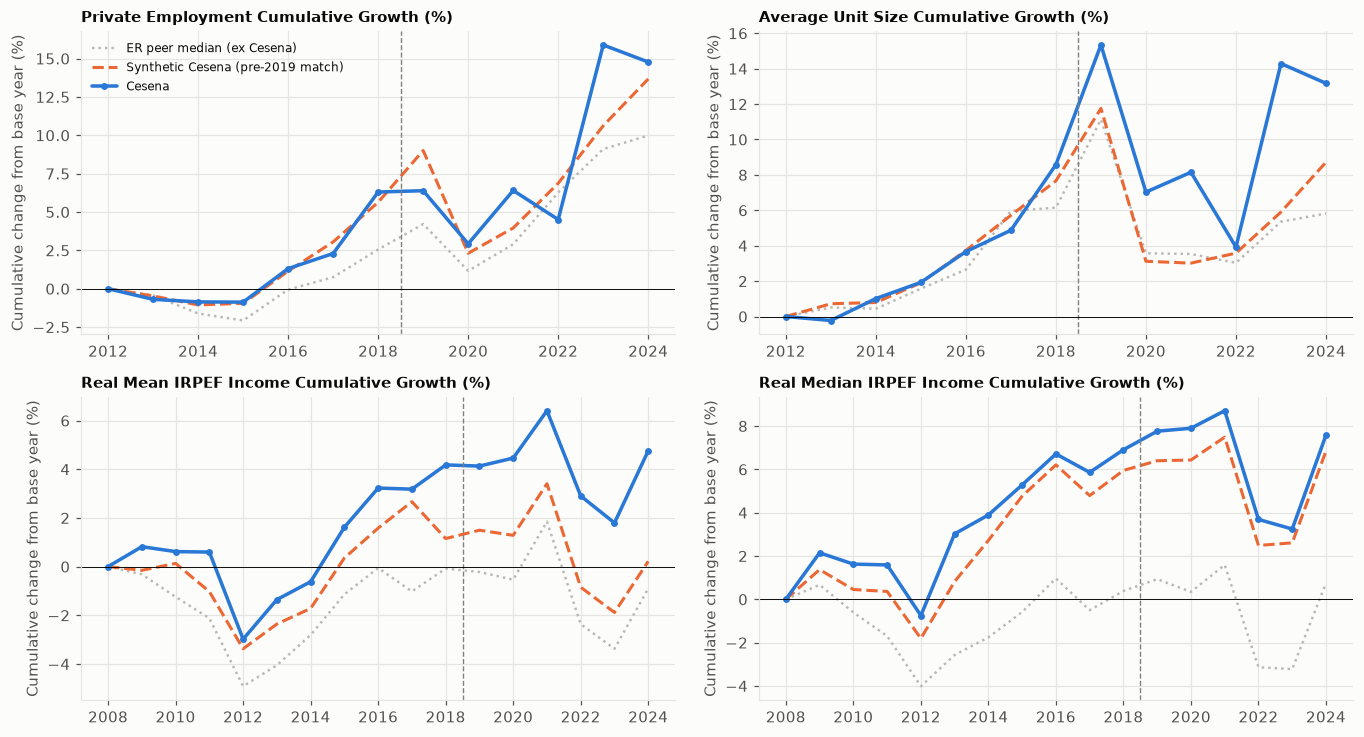

In [6]:
print("1. Extended MEF Municipal Placebo Ranking (N=36, 73 ER municipalities; N=45 Northern/Central & N=83 Italian mid-sized cities):")
display(ext_ranking[[
    "pool_label", "metric_label", "cesena_value", "peer_median_ex_cesena",
    "gap_vs_peer_median", "rank", "n_comuni", "placebo_two_sided_p", "below_05",
]].round(3))

print("\n2. Synthetic Cesena (Convex Donor Weights Matched on Pre-2019 Trajectory, Evaluated in 2024):")
display(synth_summary[[
    "label", "pre_period", "eval_year", "pre_rmse_pp",
    "cesena_end_pct", "synthetic_end_pct", "peer_median_end_pct",
    "gap_vs_synthetic_pp", "gap_vs_peer_median_pp", "donor_weights",
]].round(2))

print("\n3. Synthetic Control In-Space Placebos (Cesena Rank and Exact Permutation p among All 13 Municipalities):")
ces_space = synth_in_space[synth_in_space["is_cesena"]].copy()
display(ces_space[[
    "label", "gap_end_pp", "rank_gap_desc", "perm_p_gap",
    "ratio_post_pre_rmspe", "rank_ratio_desc", "perm_p_ratio", "n_units",
]].round(3))

print("\n4. Synthetic Control In-Time Placebo (Pseudo-Treatment Year 2014, Pre-Match <= 2014):")
display(synth_in_time[[
    "label", "pseudo_year", "pre_rmse_pp", "pseudo_post_mean_gap_pp", "true_post_mean_gap_pp", "end_gap_pp",
]].round(2))

fig, axes = plt.subplots(2, 2, figsize=(12.5, 6.8))
for ax, (m_col, title) in zip(axes.flat, [
    ("employees", "Private Employment Cumulative Growth (%)"),
    ("avg_firm_size", "Average Unit Size Cumulative Growth (%)"),
    ("mean_income_real_eur", "Real Mean IRPEF Income Cumulative Growth (%)"),
    ("median_income_real_eur", "Real Median IRPEF Income Cumulative Growth (%)"),
]):
    sub = synth_series[synth_series["metric"] == m_col]
    ax.plot(sub["year"], sub["peer_median_cum_pct"], color=PEER_C, ls=":", lw=1.6, label="ER peer median (ex Cesena)")
    ax.plot(sub["year"], sub["synthetic_cesena_cum_pct"], color=EU_C, ls="--", lw=2.0, label="Synthetic Cesena (pre-2019 match)")
    ax.plot(sub["year"], sub["cesena_cum_pct"], color=ITALY_C, lw=2.3, marker="o", ms=3.5, label="Cesena")
    ax.axvline(2018.5, color="gray", lw=0.9, ls="--")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_title(title, fontsize=9.5)
    ax.set_ylabel("Cumulative change from base year (%)")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 5. The May 2023 Flood: Descriptive Comparison (2022–2025)

Municipalities are grouped by how Allegato 1 of D.L. 61/2023 lists them: whole territory (Cesena, Forlì, Faenza, Ravenna), part of the territory (Imola, Bologna) and not listed (Rimini, Reggio nell'Emilia, Parma, Modena, Piacenza, Carpi, Ferrara). A listing is a legal perimeter, not a measure of damage, and this is not a causal design.
- **Income (MEF IRPEF 2022 $\to$ 2023).**
- **Capital cash payments, all purposes (SIOPE):** from 2022 and from a 2019–21 base. PNRR works ran in the same years, and nothing here identifies reconstruction money.
- **Employment and units (ASIA 2022 $\to$ 2024):** with and without food manufacturing, because of Cesena's 2022 break.
- **Net migration (ISTAT):** internal plus international.

1. Multi-Tier Flood Impact Comparison (Median Values across Tiers):


,tier_label,n_municipalities,income_growth_22_23_pct_median,taxpayer_growth_22_23_pct_median,capitale_cassa_pc_2022_median,capitale_cassa_pc_2024_median,capitale_cassa_growth_22_24_pct_median,emp_growth_22_24_pct_median,units_growth_23_24_pct_median,real_va_growth_22_23_pct_median,net_migr_rate_2023_median,net_migr_rate_2024_median,pop_growth_22_25_pct_median
0,Cesena (Focal Municipality),1,-1.08,0.73,163.53,401.38,145.45,9.82,0.02,6.74,7.05,4.10,-0.46
1,Listed in D.L. 61/2023: whole territory,4,-1.06,0.95,158.32,401.83,133.19,4.82,0.01,5.51,7.38,6.05,0.02
2,Listed in D.L. 61/2023: part of the territory,2,-1.21,0.86,196.02,375.43,79.31,1.49,0.02,8.04,7.13,6.68,0.19
3,Not listed in D.L. 61/2023,7,-1.25,1.50,194.79,289.28,86.30,5.42,0.26,2.32,8.31,8.45,1.02



2. City-Level Shock & Resilience Profile across Severely Impacted Poles vs Controls:


,comune_name,flood_tier,income_growth_22_23_pct,taxpayer_growth_22_23_pct,capitale_cassa_pc_2022,capitale_cassa_pc_2024,capitale_cassa_growth_22_24_pct,emp_growth_22_24_pct,units_growth_23_24_pct,real_va_growth_22_23_pct,net_migr_rate_2023,pop_growth_22_25_pct
0,Carpi,not_listed,-0.94,1.73,128.05,250.31,95.47,2.72,-0.85,2.10,10.61,2.65
1,Ferrara,not_listed,-1.10,0.26,197.99,368.86,86.30,5.42,-0.67,-1.35,6.51,-0.61
2,Modena,not_listed,-1.25,0.93,194.79,446.82,129.39,0.53,0.65,1.33,5.32,-0.48
3,Parma,not_listed,-2.14,1.50,142.64,231.30,62.16,6.01,0.55,9.62,9.00,1.67
4,Piacenza,not_listed,-1.44,1.35,99.41,190.87,92.01,6.97,0.26,6.23,7.59,1.02
5,Reggio nell'Emilia,not_listed,-1.47,1.69,244.88,289.28,18.13,6.92,-0.19,2.32,8.31,1.40
6,Rimini,not_listed,-0.71,1.84,333.97,419.72,25.68,4.77,0.54,5.25,8.64,0.78
7,Bologna,part_territory,-1.93,0.76,283.56,585.99,106.65,2.30,0.24,4.37,7.93,0.60
8,Imola,part_territory,-0.49,0.96,108.48,164.86,51.97,0.69,-0.20,11.70,6.33,-0.21
9,Cesena,whole_territory,-1.08,0.73,163.53,401.38,145.45,9.82,0.02,6.74,7.05,-0.46


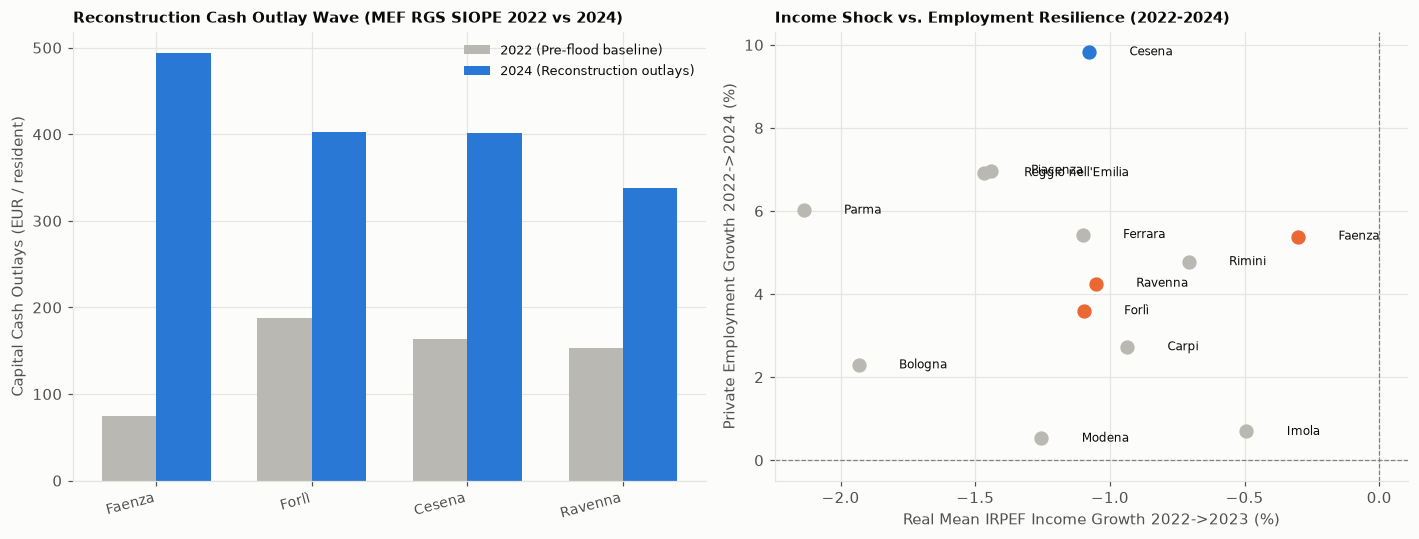

In [7]:
print("1. Multi-Tier Flood Impact Comparison (Median Values across Tiers):")
display(flood_tiers[[
    "tier_label", "n_municipalities",
    "income_growth_22_23_pct_median", "taxpayer_growth_22_23_pct_median",
    "capitale_cassa_pc_2022_median", "capitale_cassa_pc_2024_median", "capitale_cassa_growth_22_24_pct_median",
    "emp_growth_22_24_pct_median", "units_growth_23_24_pct_median", "real_va_growth_22_23_pct_median",
    "net_migr_rate_2023_median", "net_migr_rate_2024_median", "pop_growth_22_25_pct_median",
]].round(2))

print("\n2. City-Level Shock & Resilience Profile across Severely Impacted Poles vs Controls:")
display(flood_df[[
    "comune_name", "flood_tier",
    "income_growth_22_23_pct", "taxpayer_growth_22_23_pct",
    "capitale_cassa_pc_2022", "capitale_cassa_pc_2024", "capitale_cassa_growth_22_24_pct",
    "emp_growth_22_24_pct", "units_growth_23_24_pct", "real_va_growth_22_23_pct",
    "net_migr_rate_2023", "pop_growth_22_25_pct",
]].round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.0, 5.0))

# Left panel: Capital Reconstruction Cash Surge (2022 vs 2024)
sub_sev = flood_df[flood_df["flood_tier"] == "whole_territory"].sort_values("capitale_cassa_pc_2024", ascending=False)
x = np.arange(len(sub_sev))
w = 0.35
ax1.bar(x - w/2, sub_sev["capitale_cassa_pc_2022"], width=w, color=PEER_C, label="2022 (Pre-flood baseline)")
ax1.bar(x + w/2, sub_sev["capitale_cassa_pc_2024"], width=w, color=ITALY_C, label="2024 (Reconstruction outlays)")
ax1.set_xticks(x)
ax1.set_xticklabels(sub_sev["comune_name"], rotation=15, ha="right", fontsize=9)
ax1.set_ylabel("Capital Cash Outlays (EUR / resident)")
ax1.set_title("Reconstruction Cash Outlay Wave (MEF RGS SIOPE 2022 vs 2024)", fontsize=10)
ax1.legend(fontsize=8.5)

# Right panel: Income shock vs Employment Resilience
for _, r in flood_df.iterrows():
    c = ITALY_C if r["is_cesena"] else (EU_C if r["flood_tier"] == "whole_territory" else PEER_C)
    ax2.scatter(r["income_growth_22_23_pct"], r["emp_growth_22_24_pct"], color=c, s=70, zorder=3)
    ax2.text(r["income_growth_22_23_pct"] + 0.15, r["emp_growth_22_24_pct"], r["comune_name"], fontsize=8, va="center")
ax2.axvline(0, color="gray", lw=0.8, ls="--")
ax2.axhline(0, color="gray", lw=0.8, ls="--")
ax2.set_xlabel("Real Mean IRPEF Income Growth 2022->2023 (%)")
ax2.set_ylabel("Private Employment Growth 2022->2024 (%)")
ax2.set_title("Income Shock vs. Employment Resilience (2022-2024)", fontsize=10)

plt.tight_layout()
plt.show()

## 6. Sensitivity Under the Rules Fixed by the 2026-10-30 Review

All pool results with corrected q-values, how the rank moves across size windows and regions, the synthetic control without each donor, the fixed-effects screen with regime effects, and the repeated shuffled null.

In [8]:
P = "data/processed/cesena/"
display(pd.read_parquet(P + "extended_placebo_ranking.parquet")[["pool_key", "metric", "rank", "n_comuni", "placebo_two_sided_p", "q_bh", "is_main_pool"]].round(3))
s_pool = pd.read_parquet(P + "extended_pool_sensitivity.parquet")
display(s_pool[s_pool["metric"].str.startswith("mean")].pivot(index="taxpayers_lo", columns="region", values="rank"))
space = pd.read_parquet(P + "synthetic_in_space.parquet")
display(space[space["is_cesena"]][["metric", "gap_end_pp", "rank_gap_desc", "ratio_post_pre_rmspe", "rank_ratio_desc"]].round(2))
display(pd.read_parquet(P + "synthetic_in_time.parquet").drop(columns="label").round(2))
display(pd.read_parquet(P + "synthetic_leave_one_out.parquet").drop(columns="label").round(2))
regime = pd.read_parquet(P + "lagged_fe_regime_results.parquet")
print("Regime-effects screen: valid tests", int(regime["p_perm"].notna().sum()), "smallest q", round(float(regime["q_bh_perm"].min()), 3))
display(pd.read_parquet(P + "shuffled_null.parquet").round(3))

,pool_key,metric,rank,n_comuni,placebo_two_sided_p,q_bh,is_main_pool
0,ER_15k_payers,mean_income_growth_08_24_pct,4,36,0.222,0.342,False
1,ER_15k_payers,median_income_growth_08_24_pct,6,36,0.333,0.381,False
2,ER_15k_payers,addizionale_real_per_payer,5,36,0.278,0.342,False
3,ER_15k_payers,gini_change_08_24_pts,10,36,0.556,0.593,False
4,ER_10k_payers,mean_income_growth_08_24_pct,7,73,0.192,0.342,False
5,ER_10k_payers,median_income_growth_08_24_pct,10,73,0.274,0.342,False
6,ER_10k_payers,addizionale_real_per_payer,9,73,0.247,0.342,False
7,ER_10k_payers,gini_change_08_24_pts,24,73,0.658,0.658,False
8,NC_midsize_40k_120k,mean_income_growth_08_24_pct,1,45,0.044,0.193,True
9,NC_midsize_40k_120k,median_income_growth_08_24_pct,1,45,0.044,0.193,True


region,Emilia-Romagna,Italy,North and Centre
taxpayers_lo,,,
10000,7,100,39
20000,4,19,10
30000,1,6,3
40000,1,2,1
50000,1,1,1


,metric,gap_end_pp,rank_gap_desc,ratio_post_pre_rmspe,rank_ratio_desc
10,employees,1.10,7,7.00,6
23,avg_firm_size,4.45,3,8.23,2
36,mean_income_real_eur,4.54,1,2.62,6
49,median_income_real_eur,0.73,4,1.04,10


,metric,pseudo_year,pre_rmse_pp,pseudo_post_mean_gap_pp,true_post_mean_gap_pp,end_gap_pp
0,employees,2014,0.00,-0.58,1.17,3.15
1,avg_firm_size,2014,0.19,-0.59,-0.70,2.94
2,mean_income_real_eur,2014,0.81,2.81,4.65,5.28
3,median_income_real_eur,2014,1.24,0.76,1.10,0.73


,metric,dropped,weight_dropped,gap_end_pp,pre_rmse_pp
0,employees,none,0.00,1.10,0.40
1,employees,Parma,0.11,1.12,0.46
2,employees,Reggio nell'Emilia,0.58,3.51,0.52
3,employees,Faenza,0.31,0.90,0.52
4,avg_firm_size,none,0.00,4.45,0.60
5,avg_firm_size,Reggio nell'Emilia,0.54,5.43,0.67
6,avg_firm_size,Faenza,0.21,4.23,0.63
7,avg_firm_size,Rimini,0.24,4.26,0.65
8,mean_income_real_eur,none,0.00,4.54,1.35
9,mean_income_real_eur,Ferrara,0.93,2.75,1.73


Regime-effects screen: valid tests 140 smallest q 0.345


,n_tests,n_rep,n_discoveries_q_perm_05,n_discoveries_q_cluster_05,share_runs_with_discovery,min_q_perm,min_p_perm
0,140,20,14,3,0.25,0.017,0.0


## 6b. Every Emilia-Romagna Municipality by Taxpayer Class

The wider pools put Cesena lower as smaller municipalities enter. Here every municipality of the region (any size, joined 2008-2024 by cadastral code; those created by a merger after 2008 drop out) is grouped by its 2024 taxpayers. A mean over few taxpayers moves with a handful of incomes, so small classes spread more and fill both tails: a lower rank in a pool with many small municipalities is expected even without any difference in the typical municipality.

In [9]:
from cifresignificative.studies.cesena.analysis.experiments import mef_region_universe, size_class_growth

er_all = mef_region_universe()
print(f"Emilia-Romagna municipalities in both years: {len(er_all)}; dropped by mergers: {len(er_all.attrs['dropped'])} ({', '.join(er_all.attrs['dropped'])})")
classes = size_class_growth(er_all, top=5)
print(f"Cesena: {classes['focal_value'].iloc[0]:+.2f}%; other municipalities growing more: {int(classes['n_above'].sum())} of {int(classes['n'].sum())}")
display(classes.drop(columns="focal_value").round(2))
print("Municipalities above 40k taxpayers:", sorted(er_all.loc[er_all["taxpayers_total"] >= 40000, "comune"]))

Emilia-Romagna municipalities in both years: 317; dropped by mergers: 13 (ALTA VAL TIDONE, ALTO RENO TERME, FISCAGLIA, MONTESCUDO-MONTE COLOMBO, POGGIO TORRIANA, POLESINE ZIBELLO, RIVA DEL PO, SISSA TRECASALI, SORBOLO MEZZANI, TERRE DEL RENO, TRESIGNANA, VALSAMOGGIA, VENTASSO)
Cesena: +4.76%; other municipalities growing more: 110 of 316


,lo,hi,n,median,sd,n_above,top_above
0,0,2000.0,69,8.34,8.39,51,"[Piozzano, Varsi, Ferriere, Montecreto, Albareto]"
1,2000,5000.0,93,3.22,5.53,37,"[Civitella Di Romagna, Bettola, Sestola, Caste..."
2,5000,10000.0,82,1.23,3.62,16,"[Gatteo, Castelnovo Ne' Monti, Mercato Saracen..."
3,10000,20000.0,47,0.27,2.96,3,"[Bagnacavallo, Misano Adriatico, Castelnuovo R..."
4,20000,40000.0,13,1.71,3.10,3,"[Cervia, Cesenatico, Lugo]"
5,40000,inf,12,-0.90,1.63,0,[]


Municipalities above 40k taxpayers: ['BOLOGNA', 'CARPI', 'CESENA', 'FAENZA', 'FERRARA', "FORLI'", 'IMOLA', 'MODENA', 'PARMA', 'PIACENZA', 'RAVENNA', "REGGIO NELL'EMILIA", 'RIMINI']


## Takeaways (Phase 3 — Evaluation; Descriptive)

- **Wider pools (`sensitive`).** The income rank is high among mid-sized cities and falls as smaller municipalities enter. No pool result stands out after correction, and the pools were examined after Cesena's rank was known.
- **Size classes in Emilia-Romagna (descriptive).** Of the 316 other municipalities (13 merged ones drop out), 110 grew more than Cesena, all with fewer than 40k taxpayers; none of the 12 above 40k did (they are the 12 peers). The class median falls from +8.34% under 2k taxpayers to -0.90% above 40k, and the standard deviation from 8.39 to 1.63 points.
- **Synthetic control (`sensitive`).** The mean-income gap is the largest of the 13 at the end, but it is already present before 2019 and rests on one donor. On the RMSPE ratio it is mid-table. The median-income, employment and unit-size results are weak or inherit the food-sector break.
- **Lagged fixed effects.** No discoveries. With 13 cities this has little power, so it does not show that budgets have no effect. The test also over-rejects on shuffled data, so it could not support a positive result.
- **Flood (`sensitive`; the income shock is `retracted`).** No visible income shock in any group: the earlier fall in Faenza and Imola came from a blank bracket in the source. Capital payments rose in most cities, with listed cities higher, and nothing identifies reconstruction money.
- **Limits.** All statements are descriptive associations for one municipality, never causal claims. The figures are in the table below and in `reports/findings.md`, both computed by `analysis/claims.py`.

In [10]:
from cifresignificative.studies.cesena.analysis.claims import claims_for_notebook

print("Figures behind this notebook, computed from the processed tables (the same ones quoted in reports/findings.md):")
with pd.option_context("display.max_rows", None, "display.max_colwidth", 60):
    display(claims_for_notebook("05"))

Figures behind this notebook, computed from the processed tables (the same ones quoted in reports/findings.md):


,id,text,window,source
0,pool_nc45_mean,+4.76%,2008-2024,extended_placebo_ranking.parquet
1,pool_nc45_mean_rank,#1 of 45,2008-2024,extended_placebo_ranking.parquet
2,pool_nc45_mean_peer,-2.64%,2008-2024,extended_placebo_ranking.parquet
3,pool_nc45_median,+7.58%,2008-2024,extended_placebo_ranking.parquet
4,pool_nc45_median_rank,#1 of 45,2008-2024,extended_placebo_ranking.parquet
5,pool_nc45_median_peer,-0.61%,2008-2024,extended_placebo_ranking.parquet
6,pool_it83_mean,+4.76%,2008-2024,extended_placebo_ranking.parquet
7,pool_it83_mean_rank,#2 of 83,2008-2024,extended_placebo_ranking.parquet
8,pool_it83_mean_peer,-2.80%,2008-2024,extended_placebo_ranking.parquet
9,pool_it83_median,+7.58%,2008-2024,extended_placebo_ranking.parquet
